# Multi-agent ORCA-MPPI on Bench-MR with RRT-Connect anchors

This notebook runs two published tasks from the same Bench-MR `parking1` world concurrently. Bidirectional RRT-Connect generates a collision-free global polyline for each agent, shortcut smoothing turns it into an anchor path, and ORCA-MPPI follows those anchors while handling agent-agent and static-obstacle collisions.

![RRT-Connect multi-agent animation](rrt_connect_multiagent.gif)

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Circle, Polygon as PolygonPatch
import numpy as np
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if ROOT.name in {'benchmarks', 'example'}:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'benchmarks'))
sys.path.insert(0, str(ROOT / 'example'))

from bench_mr import boundary_obstacles
from rrt_connect import RRTConnectPlanner
import dyn_models
from params_names import *
import utils

suite = json.loads((ROOT / 'benchmarks/bench_mr_tasks.json').read_text())

## Select compatible Bench-MR tasks

`parking1_2` and `testing_parking1` are published tasks with valid, distinct starts and goals in the same map. They are executed simultaneously as two agents; their coordinates are not modified.

In [2]:
TASK_IDS = ['parking1_2', 'testing_parking1']
SEED = 42
ROBOT_RADIUS = 0.3
PLANNER_CLEARANCE = 0.08

tasks_by_id = {task['id']: task for task in suite['tasks']}
tasks = [tasks_by_id[task_id] for task_id in TASK_IDS]
world_names = {task['world'] for task in tasks}
if len(world_names) != 1:
    raise ValueError('Concurrent agents must use tasks from the same Bench-MR world')
world_name = world_names.pop()
world = suite['worlds'][world_name]
print(f'World: {world_name}; agents: {TASK_IDS}; obstacles: {len(world["obstacles"])}')

World: parking1; agents: ['parking1_2', 'testing_parking1']; obstacles: 13


## Generate and smooth anchor paths

Obstacles are inflated by `ROBOT_RADIUS + PLANNER_CLEARANCE`, so every returned line segment is valid for the circular robot rather than only for its center point. The raw tree path is retained for comparison; MPPI receives the smoothed path.

In [3]:
planning_results = []
for agent_id, task in enumerate(tasks):
    planner = RRTConnectPlanner(
        obstacles=world['obstacles'],
        bounds=world['bounds'],
        robot_radius=ROBOT_RADIUS,
        clearance=PLANNER_CLEARANCE,
        step_size=0.6,
        max_iterations=20_000,
        goal_sample_rate=0.05,
        smoothing_iterations=400,
        seed=SEED + agent_id,
    )
    result = planner.plan(task['start'][:2], task['goal'][:2])
    planning_results.append(result)
    raw_length = sum(np.linalg.norm(np.subtract(b, a)) for a, b in zip(result.raw_path, result.raw_path[1:]))
    smooth_length = sum(np.linalg.norm(np.subtract(b, a)) for a, b in zip(result.path, result.path[1:]))
    print(
        f"{task['id']}: iterations={result.iterations}, "
        f"raw={len(result.raw_path)} vertices/{raw_length:.2f} units, "
        f"smoothed={len(result.path)} vertices/{smooth_length:.2f} units"
    )

anchor_paths = [result.path for result in planning_results]

parking1_2: iterations=0, raw=2 vertices/2.28 units, smoothed=2 vertices/2.28 units
testing_parking1: iterations=9, raw=19 vertices/10.44 units, smoothed=4 vertices/8.55 units


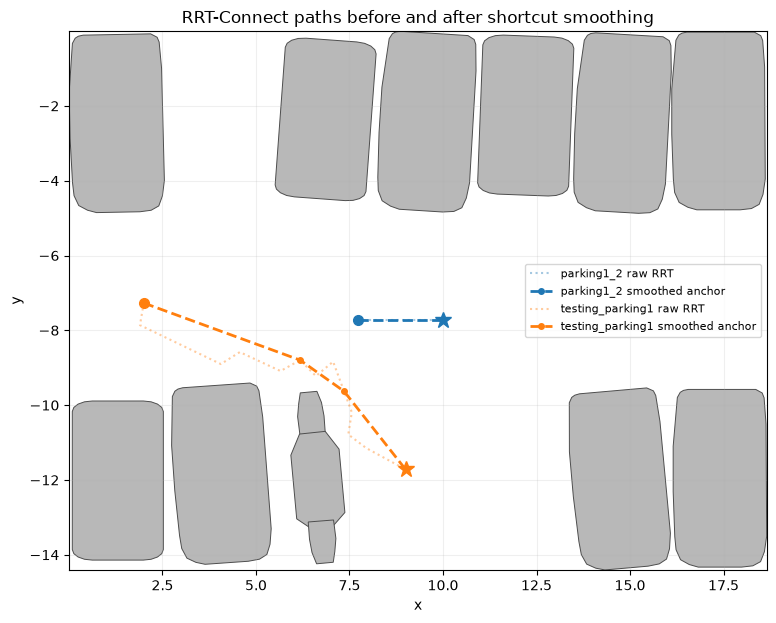

In [4]:
colors = plt.colormaps['tab10'](np.arange(len(tasks)))

def draw_world(ax):
    for polygon in world['obstacles']:
        ax.add_patch(PolygonPatch(polygon, closed=True, facecolor='0.72',
                                  edgecolor='0.3', linewidth=0.7))
    bounds = world['bounds']
    ax.set(xlim=(bounds[0], bounds[2]), ylim=(bounds[1], bounds[3]),
           aspect='equal', xlabel='x', ylabel='y')
    ax.grid(alpha=0.2)

fig, ax = plt.subplots(figsize=(9, 7))
draw_world(ax)
for agent_id, (task, result) in enumerate(zip(tasks, planning_results)):
    raw = np.asarray(result.raw_path)
    anchor = np.asarray(result.path)
    color = colors[agent_id]
    ax.plot(raw[:, 0], raw[:, 1], ':', color=color, alpha=0.4,
            label=f"{task['id']} raw RRT")
    ax.plot(anchor[:, 0], anchor[:, 1], '--o', color=color, linewidth=2,
            markersize=4, label=f"{task['id']} smoothed anchor")
    ax.plot(*task['start'][:2], 'o', color=color, markersize=7)
    ax.plot(*task['goal'][:2], '*', color=color, markersize=12)
ax.set_title('RRT-Connect paths before and after shortcut smoothing')
ax.legend(fontsize=8, loc='best')
plt.show()

## Run both agents with ORCA-MPPI

The standard Bench-MR obstacle polygons and artificial boundary walls are passed to MPPI. RRT-Connect supplies only global anchor paths; local collision rejection and ORCA remain active.

In [5]:
AGENTS_NUM = len(tasks)
DT = 0.1
start_states = np.asarray([task['start'] + [0.0, 0.0] for task in tasks], dtype=float)
goal_states = np.asarray([task['goal'] + [0.0, 0.0] for task in tasks], dtype=float)

default_agent_params = {
    AGENT_SIZE: ROBOT_RADIUS, VISIBILITY_RADIUS: 30.0,
    DIFF_DRIVE_V_MAX: 1.0, DIFF_DRIVE_V_MIN: -0.01,
    DIFF_DRIVE_W_MAX: 2.0, DIFF_DRIVE_W_MIN: -2.0,
}
agents_params = [default_agent_params.copy() for _ in range(AGENTS_NUM)]
agent_models = [dyn_models.DiffDriveDyn() for _ in range(AGENTS_NUM)]

alg_params = {
    SAMPLE_BATCH_SIZE: 700, SAMPLE_TIME_STEPS: 20, TIME_STEP: DT,
    INIT_VALUE: np.zeros(2), CONTROL_MEAN: np.zeros(2),
    CONTROL_COV: np.diag([1.0, 6.0]),
    RUNNING_COST_WEIGH: 395.0, TERMINAL_WEIGHT: 1600.0,
    SOFTMAX_TEMPERATURE: 0.25, MA_COST_EN: True,
    MA_DIST_WEIGHT: 750.0, MA_COLLISION_WEIGHT: 1e7,
    MA_DIST_THREASHOLD: 3.5, USE_CAR_LIKE_DYN: False,
    K_ALPHA: -2.96, RAD_EPS: 0.05, VELOCITY_COST_WEIGHT: 0.5,
    TERMINAL_LOOKAHEAD_DISTANCE: 2.0, MA_EN_CLOSE_TO_GOAL_DIST: 1.0,
    MA_EN_CLOSE_TO_GOAL_TS: 3, ORCA_TIME_BOUNDARY: 1.0,
    ORCA_RESPONSIBILITY_FACTOR: 0.5, MA_EXCLUDE_COLLISION_TRAJ: True,
    VELOCITY_COST_CLOSE_TO_GOAL_DIST: 0.4, ANCHOR_PATH_WEIGHT: 1600.0,
}
exp_params = {EXP_TIME_STEP: DT, XY_GOAL_TOLERANCE: 0.3, MAX_EXP_STEPS: 400}

# Match the boundary-wall construction used by benchmarks/bench_mr.py.
expanded_bounds = np.asarray(world['bounds']) + np.array([-1, -1, 1, 1]) * (ROBOT_RADIUS + 0.05)
controller_obstacles = world['obstacles'] + boundary_obstacles(expanded_bounds)

success, collisions, steps, duration, log_state = utils.launch_mppi(
    start_states, goal_states, AGENTS_NUM, agents_params, alg_params, exp_params,
    agent_models, seed=SEED, obstacles=controller_obstacles, anchor_paths=anchor_paths,
)
states = np.asarray(log_state)
goal_errors = np.linalg.norm(states[-1, :, :2] - goal_states[:, :2], axis=1)
print(f'success={success}, collisions={collisions}, steps={steps}, wall time={duration:.2f}s')
for task, error in zip(tasks, goal_errors):
    print(f"{task['id']}: final XY error={error:.3f}")

success=True, collisions=0.0, steps=97, wall time=12.28s
parking1_2: final XY error=0.020
testing_parking1: final XY error=0.245


## Executed trajectories

Dotted lines are raw RRT tree paths, dashed lines are smoothed anchors, and solid lines are the trajectories executed by MPPI.

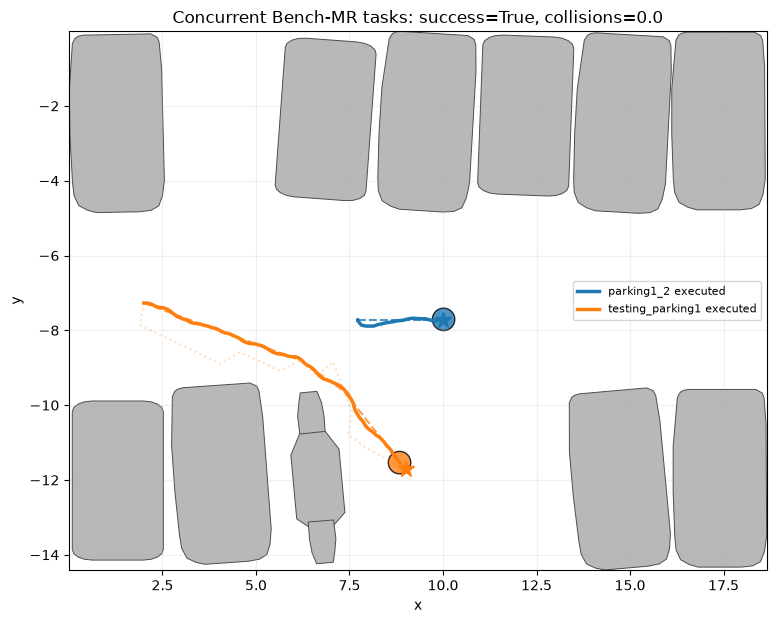

In [6]:
fig, ax = plt.subplots(figsize=(9, 7))
draw_world(ax)
for agent_id, (task, result) in enumerate(zip(tasks, planning_results)):
    color = colors[agent_id]
    raw = np.asarray(result.raw_path)
    anchor = np.asarray(result.path)
    ax.plot(raw[:, 0], raw[:, 1], ':', color=color, alpha=0.25)
    ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color, alpha=0.75, linewidth=1.5)
    ax.plot(states[:, agent_id, 0], states[:, agent_id, 1], color=color,
            linewidth=2.5, label=f"{task['id']} executed")
    ax.add_patch(Circle(states[-1, agent_id, :2], ROBOT_RADIUS,
                        facecolor=color, edgecolor='black', alpha=0.8))
    ax.plot(*task['goal'][:2], '*', color=color, markersize=12)
ax.set_title(f'Concurrent Bench-MR tasks: success={success}, collisions={collisions}')
ax.legend(fontsize=8, loc='best')
plt.show()

## Animated GIF

The smoothed RRT-Connect anchors stay visible as dashed lines in every frame. The final cell saves the GIF beside this notebook and displays it inline.

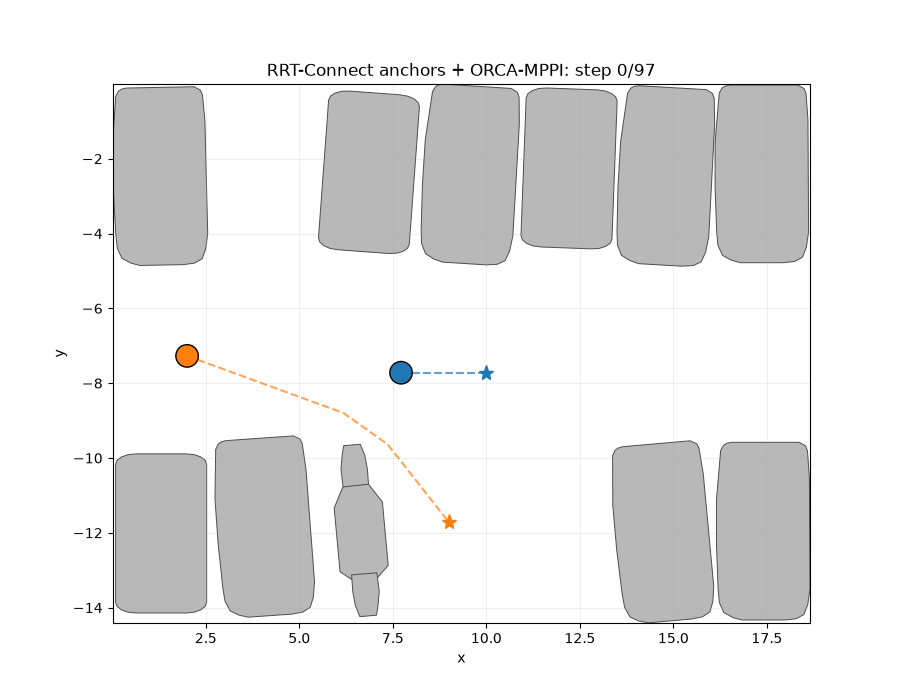

In [7]:
fig, ax = plt.subplots(figsize=(9, 7))

def animate(frame):
    ax.clear()
    draw_world(ax)
    for agent_id, (task, anchor_path) in enumerate(zip(tasks, anchor_paths)):
        color = colors[agent_id]
        anchor = np.asarray(anchor_path)
        ax.plot(anchor[:, 0], anchor[:, 1], '--', color=color, alpha=0.7, linewidth=1.5)
        ax.plot(states[:frame + 1, agent_id, 0], states[:frame + 1, agent_id, 1],
                color=color, linewidth=2.5)
        ax.add_patch(Circle(states[frame, agent_id, :2], ROBOT_RADIUS,
                            facecolor=color, edgecolor='black', zorder=4))
        ax.plot(*task['goal'][:2], '*', color=color, markersize=11, zorder=3)
    ax.set_title(f'RRT-Connect anchors + ORCA-MPPI: step {frame}/{len(states) - 1}')

animation = FuncAnimation(fig, animate, frames=len(states), interval=100)
GIF_PATH = ROOT / 'benchmarks/rrt_connect_multiagent.gif'
animation.save(GIF_PATH, writer=PillowWriter(fps=10))
plt.close(fig)
display(Image(filename=str(GIF_PATH)))